config

In [25]:
import os

import cv2
import numpy as np
from skimage.util import random_noise
import matplotlib.pyplot as plt

# Parametros do experimento
RUIDO_SIGMA = 10    # desvio padrao do ruido, em niveis de intensidade
RUIDO_SEED = 42     # seed fixa: garante que as 4 configs recebem o MESMO ruido
PASTA_SAIDA = "resultados"

FONTE_TITULO = 16      # titulo de cada painel
FONTE_SUPTITULO = 21   # titulo geral da figura

if not os.path.isdir(PASTA_SAIDA):
    os.makedirs(PASTA_SAIDA)

print("Ambiente pronto. Ruido: sigma=%d, seed=%d" % (RUIDO_SIGMA, RUIDO_SEED))

Ambiente pronto. Ruido: sigma=10, seed=42


carregando as imagens

In [26]:
IMAGENS = [
    "image1.png",
    "imagem2.jpeg",
    "imagem3.png"
]

#Le a imagem e converte para tons de cinza pela media ponderada
#O cv2 e usado apenas para abrir o arquivo.
def carregar_grayscale(caminho):

    img_bgr = cv2.imread(caminho, 1)
    if img_bgr is None:
        return None

    B, G, R = cv2.split(img_bgr)
    img_gray = 0.299 * B + 0.587 * G + 0.114 * R
    return np.array(img_gray, dtype=np.uint8)


# Carrega tudo de uma vez e avisa o que faltou
ORIGINAIS = {}
for caminho in IMAGENS:
    img = carregar_grayscale(caminho) if os.path.exists(caminho) else None
    if img is None:
        print("[AVISO] nao encontrada: %s" % caminho)
        continue
    nome = os.path.splitext(os.path.basename(caminho))[0]
    ORIGINAIS[nome] = img
    print("carregada: %-28s %d x %d" % (nome, img.shape[0], img.shape[1]))

carregada: image1                       512 x 280
carregada: imagem2                      510 x 512
carregada: imagem3                      512 x 406


CARACTERIZACAO INICIAL

imagem                          media   desvio      p1     p99
--------------------------------------------------------------
image1                           40.6     16.3       0      72
imagem2                          23.4     29.4       0      80
imagem3                          40.5     40.4       6     151
--------------------------------------------------------------
Desvio baixo + faixa p1-p99 estreita = pouco contraste.


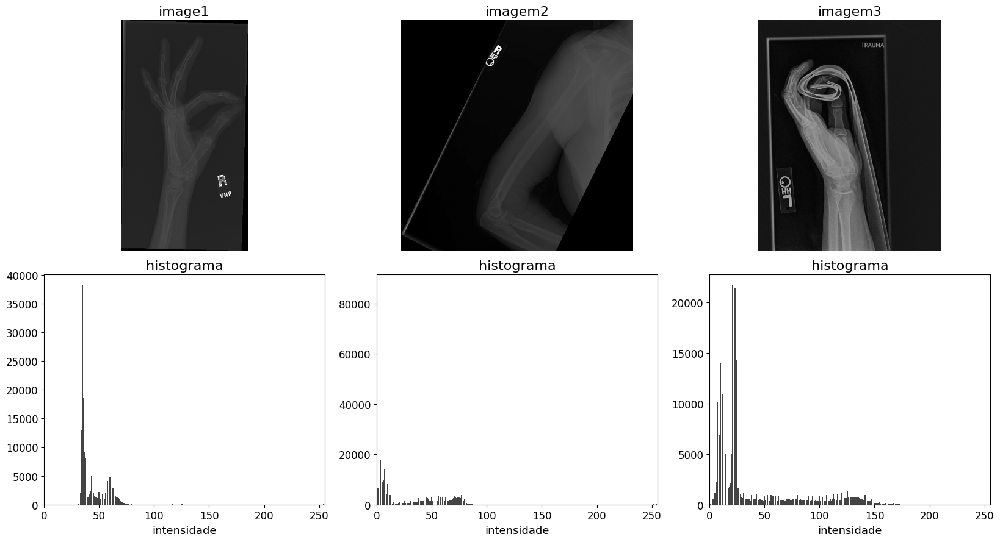

In [27]:
#Estatisticas de cada imagem + imagem e histograma lado a lado.
#
#O desvio padrao e a distancia entre os percentis 1 e 99 justificam
#objetivamente a frase "esta imagem tem baixo contraste".
#

def caracterizar(imagens):

    cabecalho = "%-28s %8s %8s %7s %7s" % (
        "imagem", "media", "desvio", "p1", "p99")
    print(cabecalho)
    print("-" * len(cabecalho))

    for nome, img in imagens.items():
        p1, p99 = np.percentile(img, 1), np.percentile(img, 99)
        print("%-28s %8.1f %8.1f %7.0f %7.0f"
              % (nome, img.mean(), img.std(), p1, p99))
    print("-" * len(cabecalho))
    print("Desvio baixo + faixa p1-p99 estreita = pouco contraste.")

    total = len(imagens)
    if total == 0:
        return

    plt.figure(figsize=(5.5 * total, 9))
    for indice, (nome, img) in enumerate(imagens.items(), start=1):
        plt.subplot(2, total, indice)
        plt.title(nome, fontsize=FONTE_TITULO)
        plt.imshow(img, cmap="gray", vmin=0, vmax=255)
        plt.axis("off")

        plt.subplot(2, total, total + indice)
        contagem, bordas = np.histogram(img, bins=256, range=(0, 255))
        plt.bar(bordas[:-1], contagem, width=1.0, color="#444444")
        plt.title("histograma", fontsize=FONTE_TITULO)
        plt.xlabel("intensidade", fontsize=FONTE_TITULO - 3)
        plt.tick_params(labelsize=FONTE_TITULO - 4)
        plt.xlim(0, 255)

    plt.tight_layout()
    plt.savefig(os.path.join(PASTA_SAIDA, "caracterizacao.png"), dpi=110)
    plt.show()


caracterizar(ORIGINAIS)

OPERACOES DE CONVOLUCAO

In [28]:
#Preenche a borda replicando o pixel mais proximo (replicate padding)
def add_padding(img, padding_height, padding_width):
    n, m = img.shape
    padded_img = np.zeros((n + padding_height * 2, m + padding_width * 2))

    # centro: a propria imagem
    padded_img[padding_height:n + padding_height,
               padding_width:m + padding_width] = img

    # linhas de cima e de baixo: copiam a primeira e a ultima linha
    for i in range(padding_height):
        padded_img[i, padding_width:m + padding_width] = img[0, :]
        padded_img[n + padding_height + i, padding_width:m + padding_width] = img[n - 1, :]

    # colunas da esquerda e da direita: copiam a coluna ja preenchida
    # mais proxima (isso tambem preenche os cantos)
    for j in range(padding_width):
        padded_img[:, j] = padded_img[:, padding_width]
        padded_img[:, m + padding_width + j] = padded_img[:, m + padding_width - 1]

    return padded_img

#Cria a distribuicao normal (gaussiana) bidimensional.
#O primeiro gaussiano remove o ruído. Ele é a etapa de suavização da pipeline e gera a img_suavizada.
def gauss_create(sigma=1, size_x=3, size_y=3):
    x, y = np.meshgrid(np.linspace(-1, 1, size_x), np.linspace(-1, 1, size_y))
    calc = 1 / (2 * np.pi * (sigma ** 2))
    exp = np.exp(-(((x ** 2) + (y ** 2)) / (2 * (sigma ** 2))))
    return exp * calc

#Gaussiana com soma 1, para o filtro nao alterar o brilho medio.
#segundo gaussiano montar a máscara do high-boost. Ele borra a img_suavizada para gerar a mascara_blur.
def gauss_normalizado(tamanho, sigma=1):
    kernel = gauss_create(sigma=sigma, size_x=tamanho, size_y=tamanho)
    return kernel / np.sum(kernel)

#Convolucao 2D para suavizacao: clipa em [0, 255] e devolve uint8.
def conv2d(img, kernel, padding=True):
    k_height, k_width = kernel.shape
    img_height, img_width = img.shape

    pad_height = k_height // 2
    pad_width = k_width // 2

    if padding:
        padded_img = add_padding(img, pad_height, pad_width)
    else:
        padded_img = img

    output = np.zeros((img_height, img_width), dtype=float)

    for i_img in range(img_height):
        for j_img in range(img_width):
            soma = 0.0
            for i_kernel in range(k_height):
                for j_kernel in range(k_width):
                    soma += (float(padded_img[i_img + i_kernel, j_img + j_kernel])
                             * kernel[i_kernel, j_kernel])

            # corte manual
            if soma > 255:
                soma = 255
            elif soma < 0:
                soma = 0
            output[i_img, j_img] = int(soma)

    return np.array(output, dtype=np.uint8)

#Convolucao 2D para agucamento: preserva os negativos.
def conv2d_sharpening(img, kernel, padding=True):
    k_height, k_width = kernel.shape
    img_height, img_width = img.shape

    pad_height = k_height // 2
    pad_width = k_width // 2

    if padding:
        padded_img = add_padding(img, pad_height, pad_width)
    else:
        padded_img = img

    output = np.zeros((img_height, img_width), dtype=np.float32)

    for i_img in range(img_height):
        for j_img in range(img_width):
            soma = 0.0
            for i_kernel in range(k_height):
                for j_kernel in range(k_width):
                    soma += (float(padded_img[i_img + i_kernel, j_img + j_kernel])
                             * kernel[i_kernel, j_kernel])
            output[i_img, j_img] = soma

    return output


print("Convolucao implementada.")

Convolucao implementada.


CELULA DA DEGRADACAO

In [29]:
#Ruido gaussiano de media zero, com sigma em niveis de intensidade.
#degradação controlada, a primeira etapa da pipeline.
def add_gaussian_noise(img, sigma=10, seed=42):
    var = (sigma / 255.0) ** 2
    try:
        img_ruidosa = random_noise(img, mode="gaussian", var=var, rng=seed)
    except TypeError:
        img_ruidosa = random_noise(img, mode="gaussian", var=var, seed=seed)

    # random_noise devolve float em [0, 1]
    return (img_ruidosa * 255).astype(np.uint8)

OPERACAO PONTUAL

In [30]:
# Alargamento linear de contraste entre os percentis 1 e 99.
# Os percentis, em vez do minimo e do maximo, evitam que um unico pixel
# extremo (o marcador metalico "R", por exemplo) determine a transformacao
#inteira.

#cada pixel é transformado sozinho: o novo valor depende só do valor antigo daquele pixel, sem olhar os vizinhos

def contrast_stretching_p1_p99(img):
    p1 = np.percentile(img, 1)
    p99 = np.percentile(img, 99)

    if p99 <= p1:
        return img.copy()

    esticada = (img.astype(np.float32) - p1) / (p99 - p1) * 255
    return np.clip(esticada, 0, 255).astype(np.uint8)


print("Operacao pontual implementada.")

Operacao pontual implementada.


CELULA DO AGUCAMENTO

In [31]:
#
#    High-boost: f_hb = f + k*(f - f_blur)
#
#   A imagem que entra como 'img' e a BASE do resultado; 'blur_img' serve
#    apenas para montar a mascara de detalhe.
#
#Com k = 1, é unsharp masking.
#Com k > 1, é high-boost.
def highboost_filter(img, blur_img, k=1):
    img_float = img.astype(np.float32)
    blur_float = blur_img.astype(np.float32)

    g = img_float - blur_float          # mascara de detalhe
    umhf = img_float + k * g            # f + k*g

    return np.clip(umhf, 0, 255).astype(np.uint8)

#Agucamento pelo laplaciano
#aproximação da segunda derivada da imagem. Ele mede o quanto um pixel é diferente da média dos seus 4 vizinhos
def laplacian_sharpening(img, c=1):

    kernel_laplaciano = np.array(([0, -1, 0],
                                  [-1, 4, -1],
                                  [0, -1, 0]), dtype=float)
    laplaciano = conv2d_sharpening(img, kernel_laplaciano)

    img_float = img.astype(np.float32)
    agucada = img_float + (c * laplaciano)

    return np.clip(agucada, 0, 255).astype(np.uint8)


print("Agucamento implementado.")

Agucamento implementado.


CELULA DAS METRICAS

In [32]:
#Erro quadratico medio. Conta interna do PSNR, nao e metrica escolhida.
#Para cada pixel, calcula a diferença entre as duas imagens, eleva ao quadrado e tira a média.
#O MSE não é uma das métricas escolhidas: ele é só a conta interna do PSNR.
def mse(img_a, img_b):

    a = img_a.astype(np.float64)
    b = img_b.astype(np.float64)
    return float(np.mean((a - b) ** 2))

#Peak Signal to Noise Ratio, em dB. Quanto maior, melhor.
#compara o maior sinal possível com o tamanho médio do erro. Quanto menor o erro, maior o PSNR. A unidade é o decibel (dB).
def psnr(img_a, img_b, L=255.0):

    erro = mse(img_a, img_b)
    if erro == 0:
        return 100.0
    return float(20 * np.log10(L / np.sqrt(erro)))

#Structural Similarity, formula da aula
#Compara as média
#Compara as variâncias, que indicam o contraste, e a covariância,
#que indica se os pixels claros e escuros estão nos mesmos lugares nas duas imagens
def ssim_global(img_a, img_b, L=255.0, k1=0.01, k2=0.03):

    a = img_a.astype(np.float64)
    b = img_b.astype(np.float64)

    #São constantes de estabilização. Evitam divisão por zero
    c1 = (k1 * L) ** 2
    c2 = (k2 * L) ** 2

    mu_a = a.mean()
    mu_b = b.mean()
    var_a = a.var()
    var_b = b.var()
    cov_ab = ((a - mu_a) * (b - mu_b)).mean()

    numerador = (2 * mu_a * mu_b + c1) * (2 * cov_ab + c2)
    denominador = (mu_a ** 2 + mu_b ** 2 + c1) * (var_a + var_b + c2)

    return float(numerador / denominador)

#calcula e cria a tabela das duas metricas escolhidas.
#Só junta as duas métricas num dicionário. A rodar chama essa função
def calcular_metricas(referencia, processada):

    return {
        "PSNR": psnr(referencia, processada),
        "SSIM": ssim_global(referencia, processada),
    }


print("Metricas implementadas (PSNR e SSIM).")

Metricas implementadas (PSNR e SSIM).


CELULA DAS CONFIGURACOES

In [33]:
#lê um dicionário de configuração e decide o que fazer a partir dele.
CONFIGURACOES = {
    "A": {
        "rotulo": "A (base)",
        "descricao": "alargamento -> gauss 3x3 -> highboost k=2",
        "muda": "configuracao de referencia",
        "ordem": "pontual_primeiro",
        "gauss": 3,
        "agucamento": "highboost",
        "k": 2.0,
    },
    "B": {
        "rotulo": "B",
        "descricao": "alargamento -> gauss 5x5 -> highboost k=2",
        "muda": "tamanho do kernel de suavizacao (3x3 -> 5x5)",
        "ordem": "pontual_primeiro",
        "gauss": 5,
        "agucamento": "highboost",
        "k": 2.0,
    },
    "C": {
        "rotulo": "C",
        "descricao": "alargamento -> gauss 3x3 -> laplaciano c=1",
        "muda": "tecnica de agucamento (highboost -> laplaciano)",
        "ordem": "pontual_primeiro",
        "gauss": 3,
        "agucamento": "laplaciano",
        "c": 1.0,
    },
    "D": {
        "rotulo": "D",
        "descricao": "gauss 3x3 -> alargamento -> highboost k=2",
        "muda": "ordem das etapas (suavizacao antes da operacao pontual)",
        "ordem": "suavizacao_primeiro",
        "gauss": 3,
        "agucamento": "highboost",
        "k": 2.0,
    },
}

for chave in sorted(CONFIGURACOES):
    cfg = CONFIGURACOES[chave]
    print("%-10s %-45s  (muda: %s)"
          % (cfg["rotulo"], cfg["descricao"], cfg["muda"]))

A (base)   alargamento -> gauss 3x3 -> highboost k=2      (muda: configuracao de referencia)
B          alargamento -> gauss 5x5 -> highboost k=2      (muda: tamanho do kernel de suavizacao (3x3 -> 5x5))
C          alargamento -> gauss 3x3 -> laplaciano c=1     (muda: tecnica de agucamento (highboost -> laplaciano))
D          gauss 3x3 -> alargamento -> highboost k=2      (muda: ordem das etapas (suavizacao antes da operacao pontual))


CELULA DO PIPELINE

In [34]:
def executar_pipeline(img_gray, cfg):
    etapas = [] #Cada etapa é adicionada nela, e é essa lista que vira a figura com os painéis.
    kernel = gauss_normalizado(cfg["gauss"])
    n = cfg["gauss"]

    # Etapa 1: degradacao controlada
    #O ruído é igual para todas as configurações
    img_ruido = add_gaussian_noise(img_gray, sigma=RUIDO_SIGMA, seed=RUIDO_SEED)
    etapas.append(("1. Degradada (ruido sigma=%d)" % RUIDO_SIGMA, img_ruido))

    #A, B e C caem no primeiro: primeiro alarga, depois suaviza.
    if cfg["ordem"] == "pontual_primeiro":
        # Etapa 2: operacao pontual
        img_contrast = contrast_stretching_p1_p99(img_ruido)
        etapas.append(("2. Alargamento p1-p99", img_contrast))

        # Etapa 3: suavizacao
        img_suavizada = conv2d(img_contrast, kernel)
        etapas.append(("3. Gauss %dx%d (sigma~%.0f px)" % (n, n, (n - 1) / 2),
                       img_suavizada)) #uma imagem já suavizada e com o contraste ajustado
    # D cai no else: primeiro suaviza, depois alarga.
    else:
        # Config D: suavizacao antes da operacao pontual
        img_suavizada_ruido = conv2d(img_ruido, kernel)
        etapas.append(("2. Gauss %dx%d (sigma~%.0f px)" % (n, n, (n - 1) / 2),
                       img_suavizada_ruido))

        img_suavizada = contrast_stretching_p1_p99(img_suavizada_ruido)
        etapas.append(("3. Alargamento p1-p99", img_suavizada)) #uma imagem já suavizada e com o contraste ajustado

    # A partir daqui TODAS as configs partem de uma imagem ja suavizada
    # e com contraste ajustado. So muda a ordem em que isso foi feito.

    # Etapa 4: agucamento
    if cfg["agucamento"] == "highboost":
        # High-boost (A, B, D): aplica um segundo gaussiano sobre img_suavizada
        # para gerar a versão borrada. A base do high-boost é img_suavizada
        mascara_blur = conv2d(img_suavizada, kernel)
        etapas.append(("3b. Gauss p/ mascara", mascara_blur))

        img_final = highboost_filter(img_suavizada, mascara_blur, k=cfg["k"])
        etapas.append(("4. High-boost k=%g" % cfg["k"], img_final))
        #Laplaciano (C): recebe a mesma img_suavizada
    else:
        img_final = laplacian_sharpening(img_suavizada, c=cfg["c"])
        etapas.append(("4. Laplaciano c=%g" % cfg["c"], img_final))

#Devolve a imagem final, a degradada e a lista de etapas para montar a figura.
    return img_final, img_ruido, etapas

FUNCOES DE FIGURA

In [35]:

#monta e salva as figuras
#    Calcula o figsize respeitando a proporcao da imagem.
#
#   O + 0.9 por linha reserva espaco para o titulo de cada painel: sem isso,
#  com fontes grandes, o titulo de uma linha invade a imagem da linha de cima.
# O + 1.4 no total e a faixa do titulo geral.

def tamanho_figura(img, colunas, linhas, largura_painel=4.2):

    proporcao = img.shape[0] / float(img.shape[1])
    altura_painel = largura_painel * proporcao + 0.9
    return (colunas * largura_painel, linhas * altura_painel + 1.4)

#Imagem original e todas as etapas de uma configuracao.
def figura_etapas(nome_img, chave, cfg, img_gray, etapas):

    paineis = [("0. Original (grayscale)", img_gray)] + etapas
    colunas = 3
    linhas = int(np.ceil(len(paineis) / colunas))

    plt.figure(figsize=tamanho_figura(img_gray, colunas, linhas))
    # Titulo em duas linhas: numa linha so ele fica mais largo que a figura e
    # as pontas sao cortadas.
    plt.suptitle("%s  -  Config %s\n%s"
                 % (nome_img, cfg["rotulo"], cfg["descricao"]),
                 fontsize=FONTE_SUPTITULO)

    for indice, (titulo, imagem) in enumerate(paineis, start=1):
        plt.subplot(linhas, colunas, indice)
        plt.title(titulo, fontsize=FONTE_TITULO)
        plt.imshow(imagem, cmap="gray", vmin=0, vmax=255)
        plt.axis("off")

    plt.tight_layout(rect=[0, 0, 1, 0.94], h_pad=2.5)
    plt.savefig(os.path.join(PASTA_SAIDA, "etapas_%s_%s.png" % (nome_img, chave)),
                dpi=110)
    plt.show()

#Original, degradada e as quatro saidas finais lado a lado.
def figura_comparacao(nome_img, img_gray, img_ruido, finais):

    paineis = [("Original", img_gray),
               ("Degradada (sigma=%d)" % RUIDO_SIGMA, img_ruido)]
    for chave in sorted(finais):
        paineis.append(("Config %s" % chave, finais[chave]))

    plt.figure(figsize=tamanho_figura(img_gray, 3, 2))
    plt.suptitle("%s - comparacao das configuracoes" % nome_img,
                 fontsize=FONTE_SUPTITULO)
    for indice, (titulo, imagem) in enumerate(paineis, start=1):
        plt.subplot(2, 3, indice)
        plt.title(titulo, fontsize=FONTE_TITULO)
        plt.imshow(imagem, cmap="gray", vmin=0, vmax=255)
        plt.axis("off")

    plt.tight_layout(rect=[0, 0, 1, 0.94], h_pad=2.5)
    plt.savefig(os.path.join(PASTA_SAIDA, "comparacao_%s.png" % nome_img), dpi=110)
    plt.show()


print("Funcoes de figura prontas.")

Funcoes de figura prontas.


Processamento

In [36]:
RESULTADOS = {}


def _preparar(numero_imagem):
    caminho = IMAGENS[numero_imagem - 1]
    nome_img = os.path.splitext(os.path.basename(caminho))[0]

    if nome_img not in RESULTADOS:
        img_gray = carregar_grayscale(caminho)
        img_ruido = add_gaussian_noise(img_gray, sigma=RUIDO_SIGMA, seed=RUIDO_SEED)
        RESULTADOS[nome_img] = {
            "gray": img_gray,
            "ruido": img_ruido,
            "ideal": contrast_stretching_p1_p99(img_gray),
            "finais": {},
            "metricas": {},
        }
    return nome_img


def rodar(chave_config, numero_imagem):
    nome_img = _preparar(numero_imagem)
    dados = RESULTADOS[nome_img]
    cfg = CONFIGURACOES[chave_config]

    img_final, _, etapas = executar_pipeline(dados["gray"], cfg)
    dados["finais"][chave_config] = img_final
    dados["metricas"][chave_config] = {
        "ideal": calcular_metricas(dados["ideal"], img_final),
        "original": calcular_metricas(dados["gray"], img_final),
        "degradada": calcular_metricas(dados["ruido"], img_final),
    }

    figura_etapas(nome_img, chave_config, cfg, dados["gray"], etapas)


def imprimir_tabela(nome_img, referencia):
    dados = RESULTADOS[nome_img]
    linhas = []

    if referencia == "ideal":
        so_pontual = contrast_stretching_p1_p99(dados["ruido"])
        linhas.append(("sem filtro", calcular_metricas(dados["ideal"], so_pontual)))
    if referencia == "original":
        linhas.append(("degradada", calcular_metricas(dados["gray"], dados["ruido"])))

    for chave in sorted(dados["metricas"]):
        linhas.append((chave, dados["metricas"][chave][referencia]))

    print("\nReferencia: %s" % referencia)
    print("%-12s %10s %10s" % ("Config", "PSNR(dB)", "SSIM"))
    for rotulo, m in linhas:
        print("%-12s %10.2f %10.4f" % (rotulo, m["PSNR"], m["SSIM"]))


def comparar(numero_imagem):
    nome_img = _preparar(numero_imagem)
    dados = RESULTADOS[nome_img]

    figura_comparacao(nome_img, dados["gray"], dados["ruido"], dados["finais"])
    for referencia in ("ideal", "original", "degradada"):
        imprimir_tabela(nome_img, referencia)


Configuracao A (base): alargamento -> gauss 3x3 -> highboost k=1

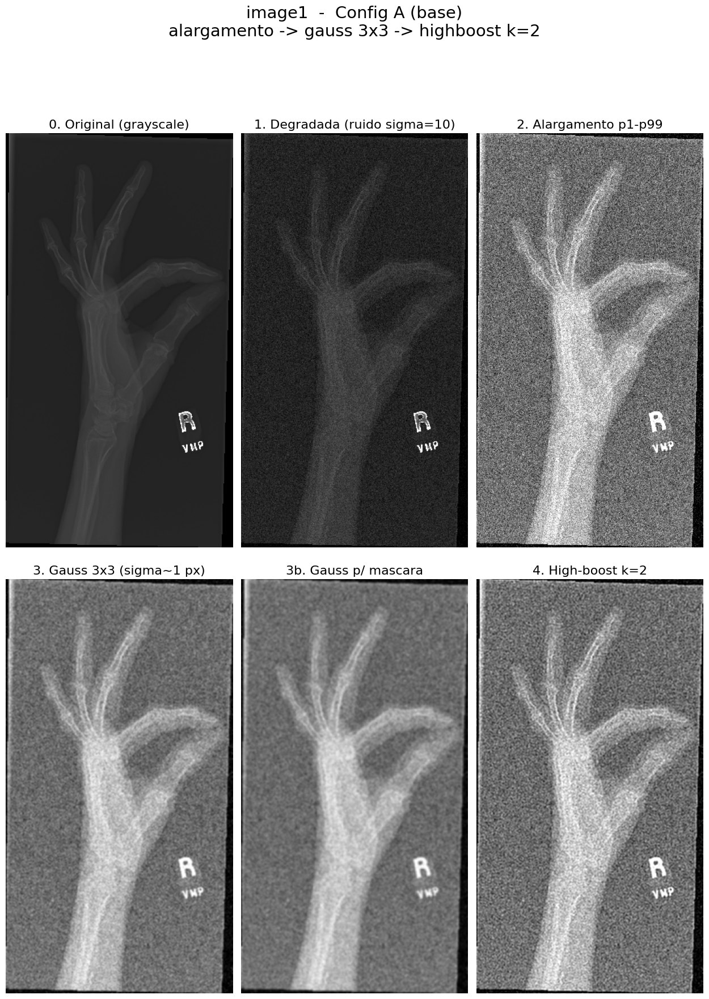

In [37]:
rodar("A", 1)

Configuracao B: alargamento -> gauss 5x5 -> highboost k=1

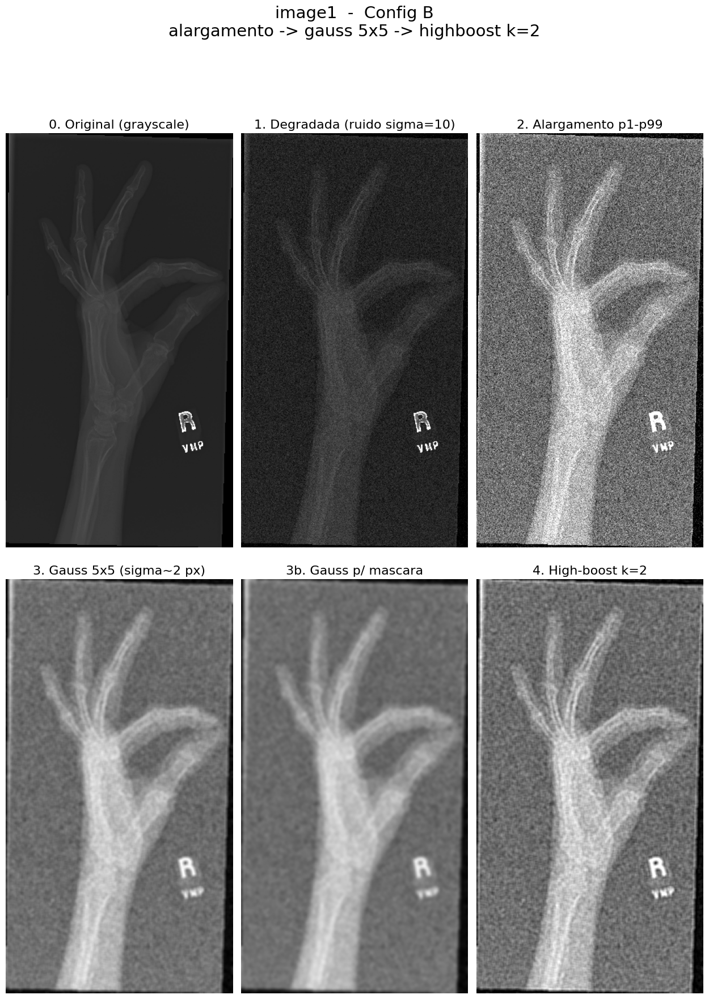

In [38]:
rodar("B", 1)

Configuracao C: alargamento -> gauss 3x3 -> laplaciano c=1

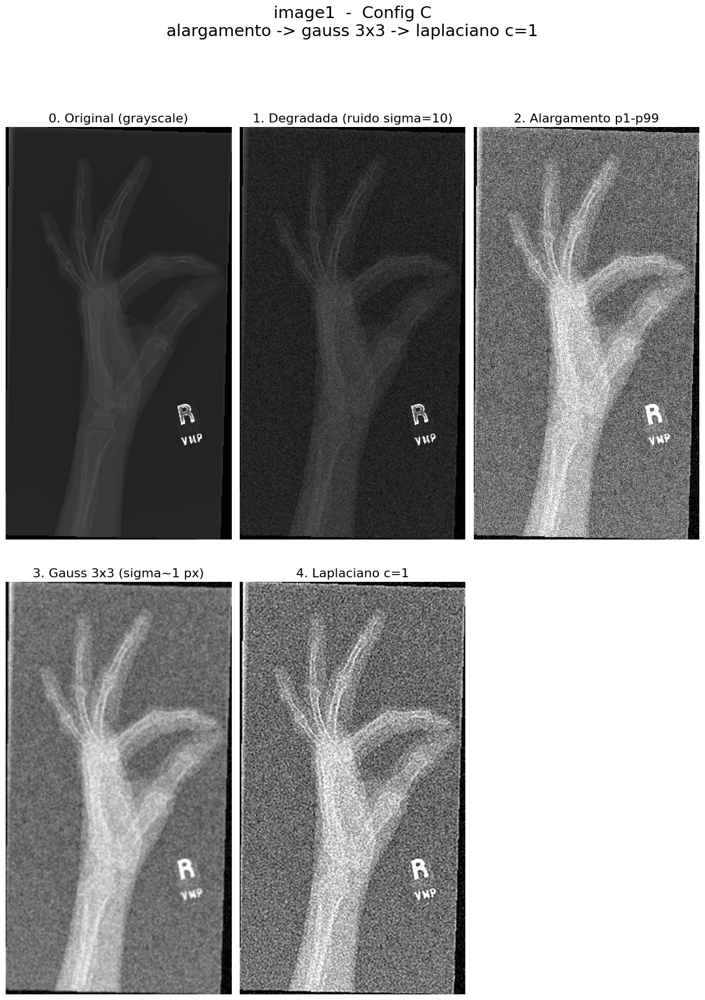

In [39]:
rodar("C", 1)

Configuracao D: gauss 3x3 -> alargamento -> highboost k=1


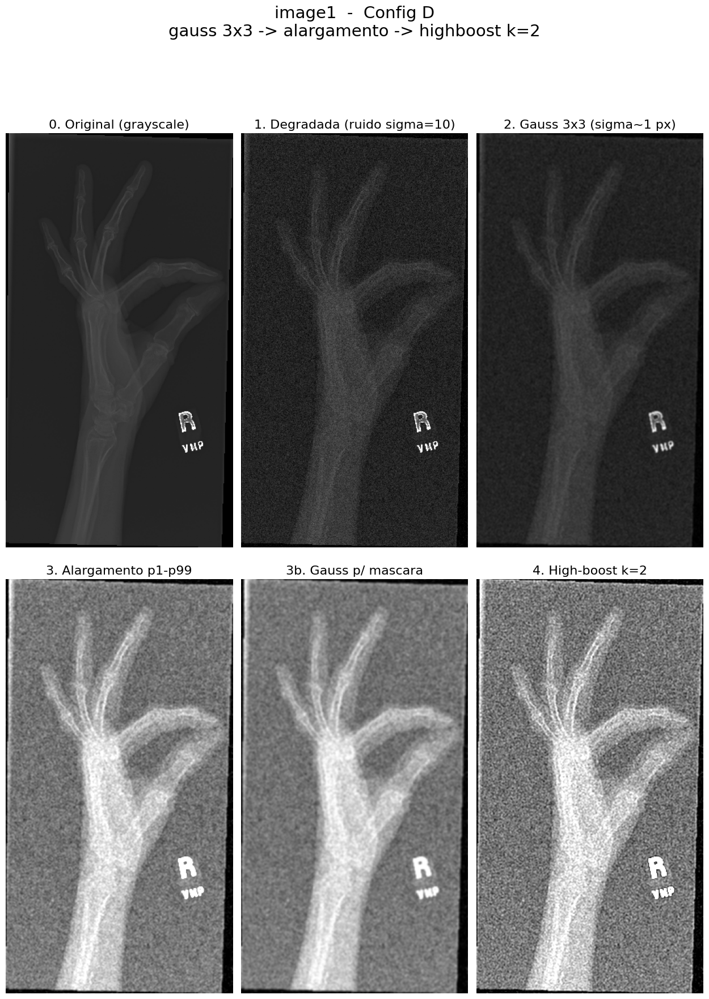

In [40]:
rodar("D", 1)

Comparacao das quatro configuracoes na imagem 1





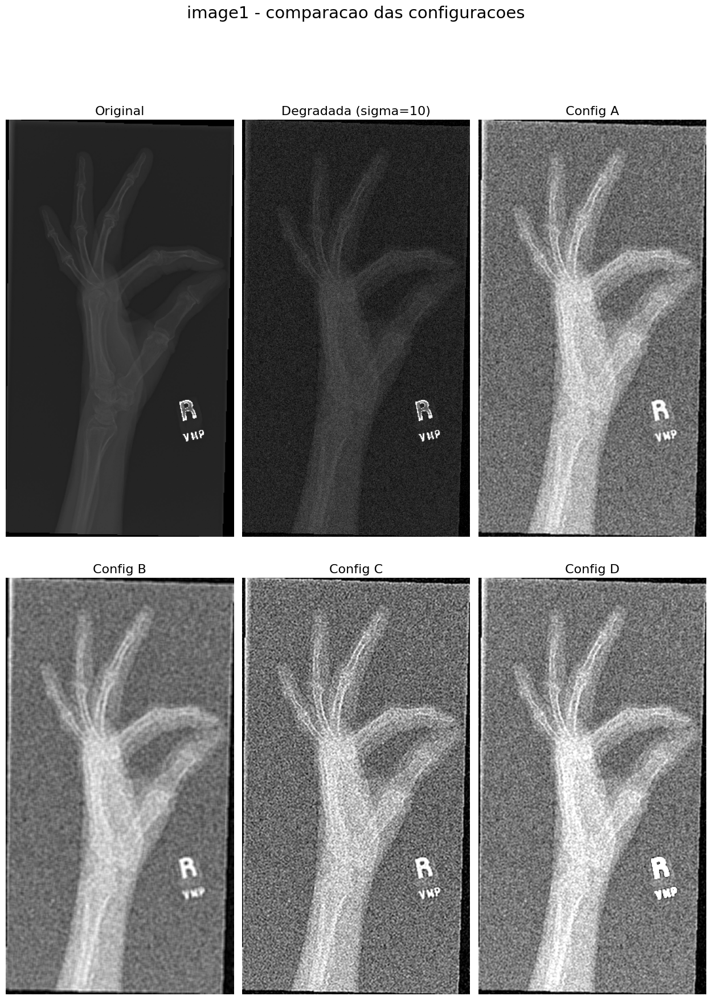


Referencia: ideal
Config         PSNR(dB)       SSIM
sem filtro        16.89     0.7924
A                 19.44     0.8941
B                 20.34     0.9215
C                 17.65     0.8295
D                 20.71     0.8972

Referencia: original
Config         PSNR(dB)       SSIM
degradada         28.19     0.8529
A                  9.08     0.3192
B                  9.18     0.3444
C                  8.95     0.2771
D                  7.94     0.2634

Referencia: degradada
Config         PSNR(dB)       SSIM
A                  9.10     0.3493
B                  9.12     0.3349
C                  9.02     0.3247
D                  7.97     0.2910


In [41]:
comparar(1)

Configuracao A (base): alargamento -> gauss 3x3 -> highboost k=1

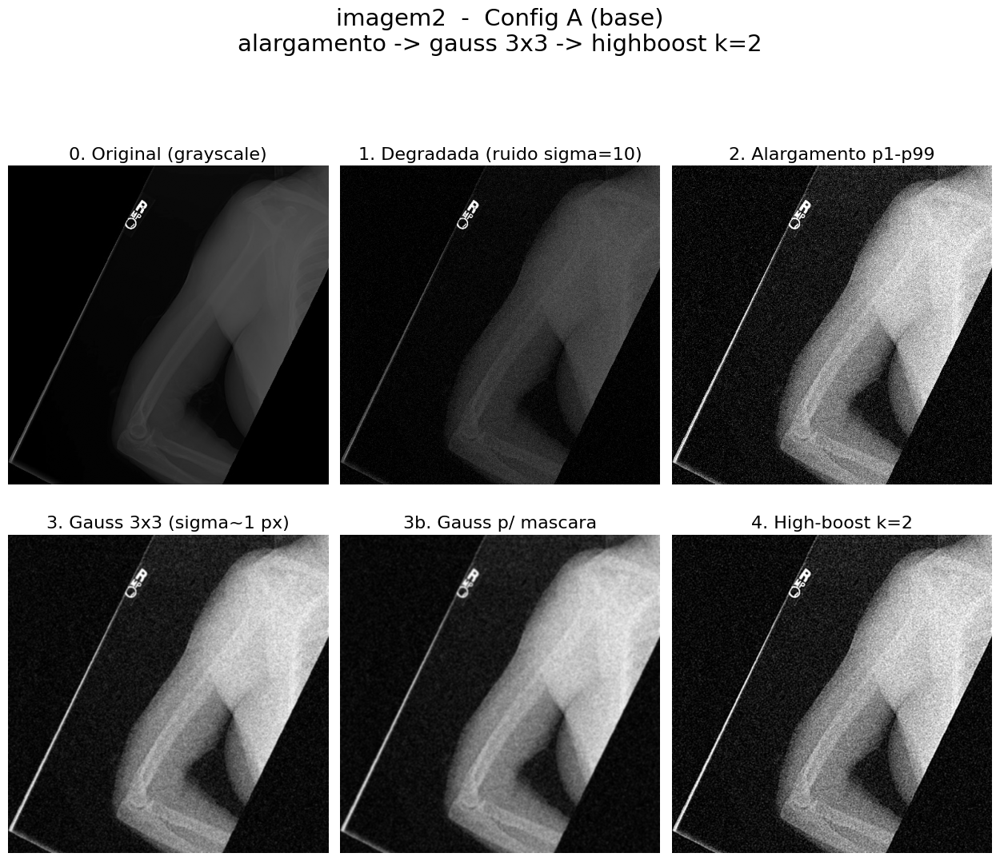

In [42]:
rodar("A", 2)

Configuracao B: alargamento -> gauss 5x5 -> highboost k=1

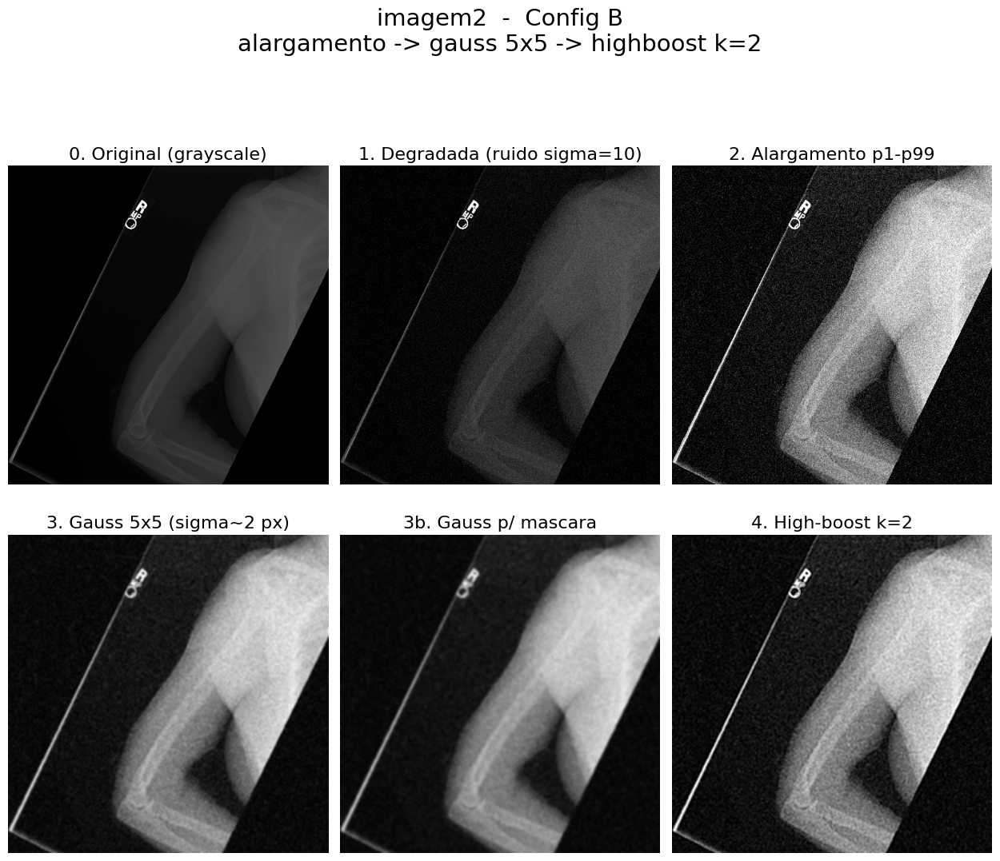

In [43]:
rodar("B", 2)

Configuracao C: alargamento -> gauss 3x3 -> laplaciano c=1

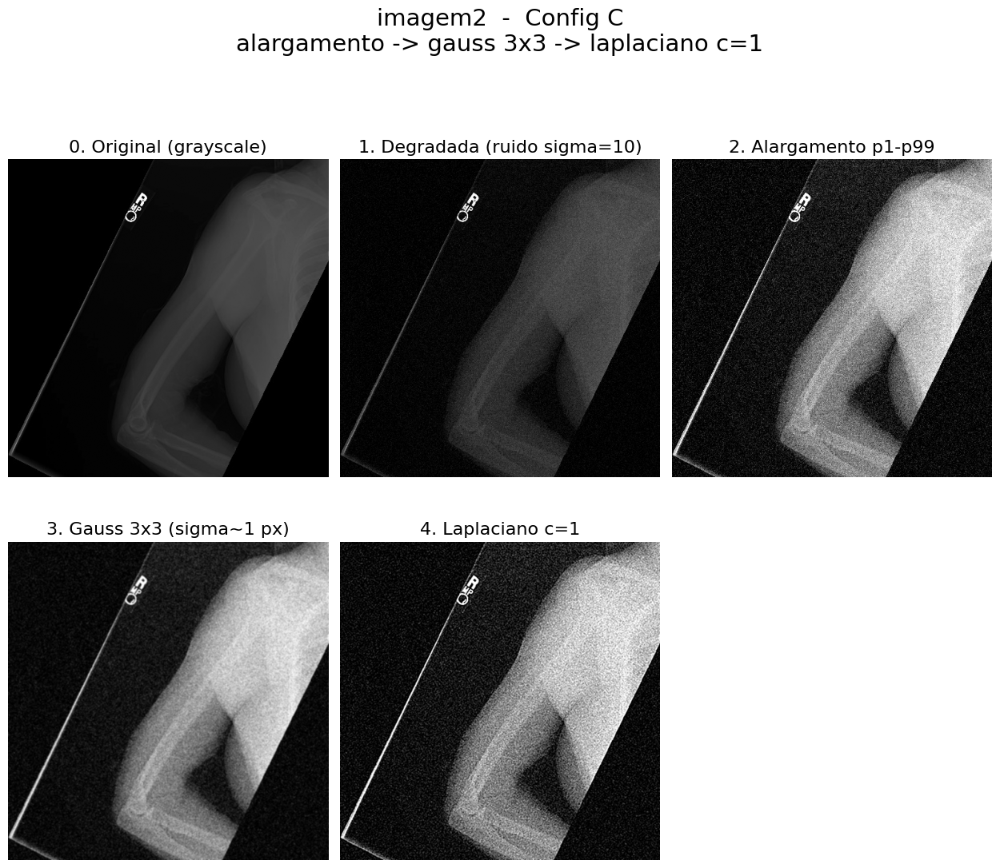

In [44]:
rodar("C", 2)

Configuracao D: gauss 3x3 -> alargamento -> highboost k=1


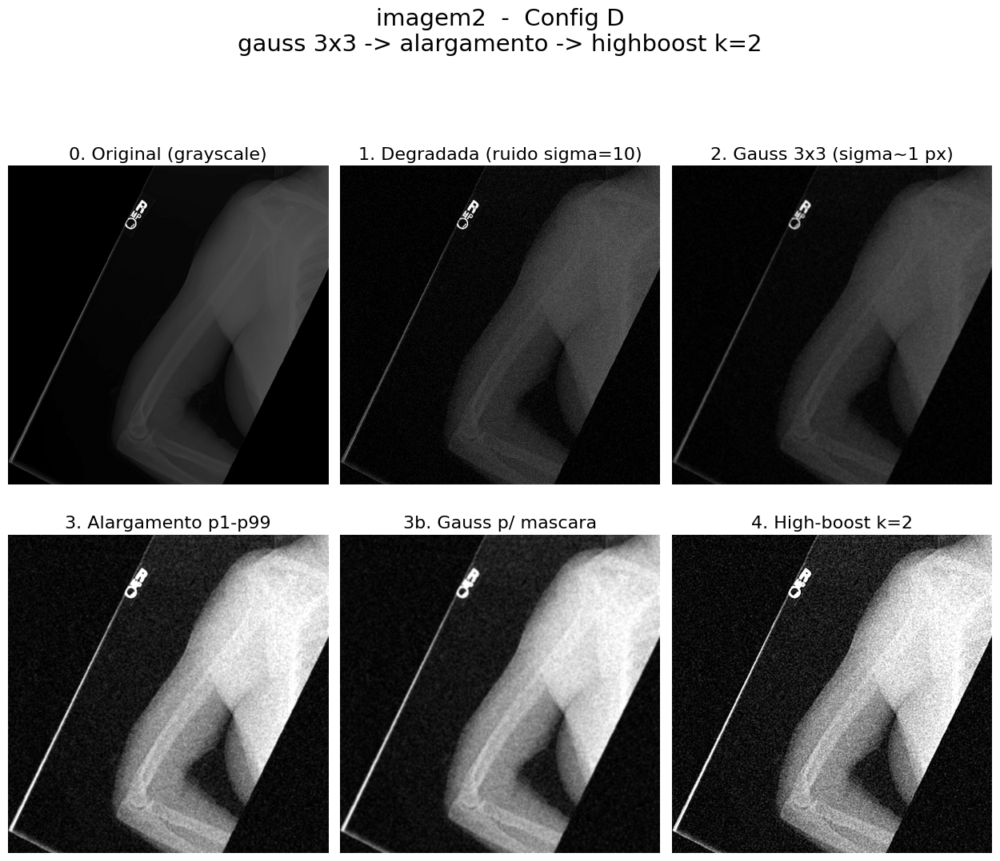

In [45]:
rodar("D", 2)

Comparacao das quatro configuracoes na imagem 2






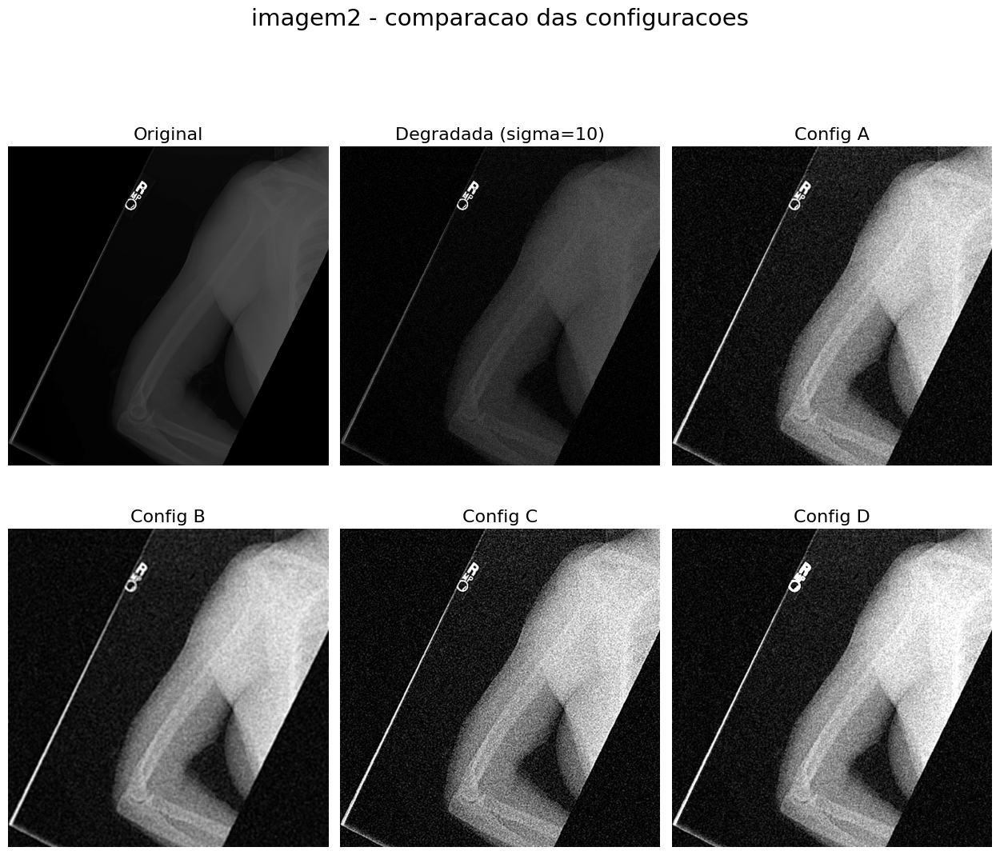


Referencia: ideal
Config         PSNR(dB)       SSIM
sem filtro        19.35     0.9458
A                 21.59     0.9667
B                 22.35     0.9718
C                 20.16     0.9544
D                 22.99     0.9782

Referencia: original
Config         PSNR(dB)       SSIM
degradada         29.63     0.9593
A                 11.71     0.3965
B                 11.80     0.4012
C                 11.60     0.3893
D                 10.29     0.3335

Referencia: degradada
Config         PSNR(dB)       SSIM
A                 11.77     0.4083
B                 11.77     0.4041
C                 11.71     0.4059
D                 10.33     0.3437


In [46]:
comparar(2)

Configuracao A (base): alargamento -> gauss 3x3 -> highboost k=1

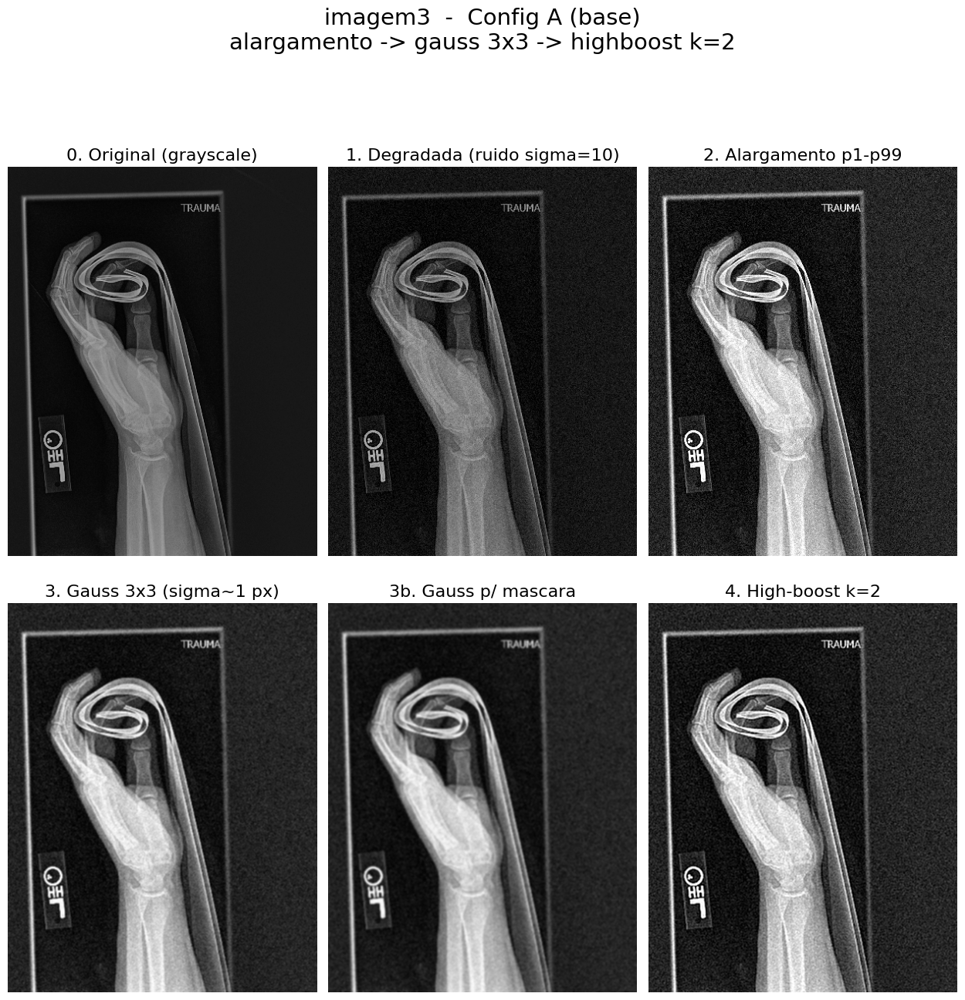

In [47]:
rodar("A", 3)

Configuracao B: alargamento -> gauss 5x5 -> highboost k=1

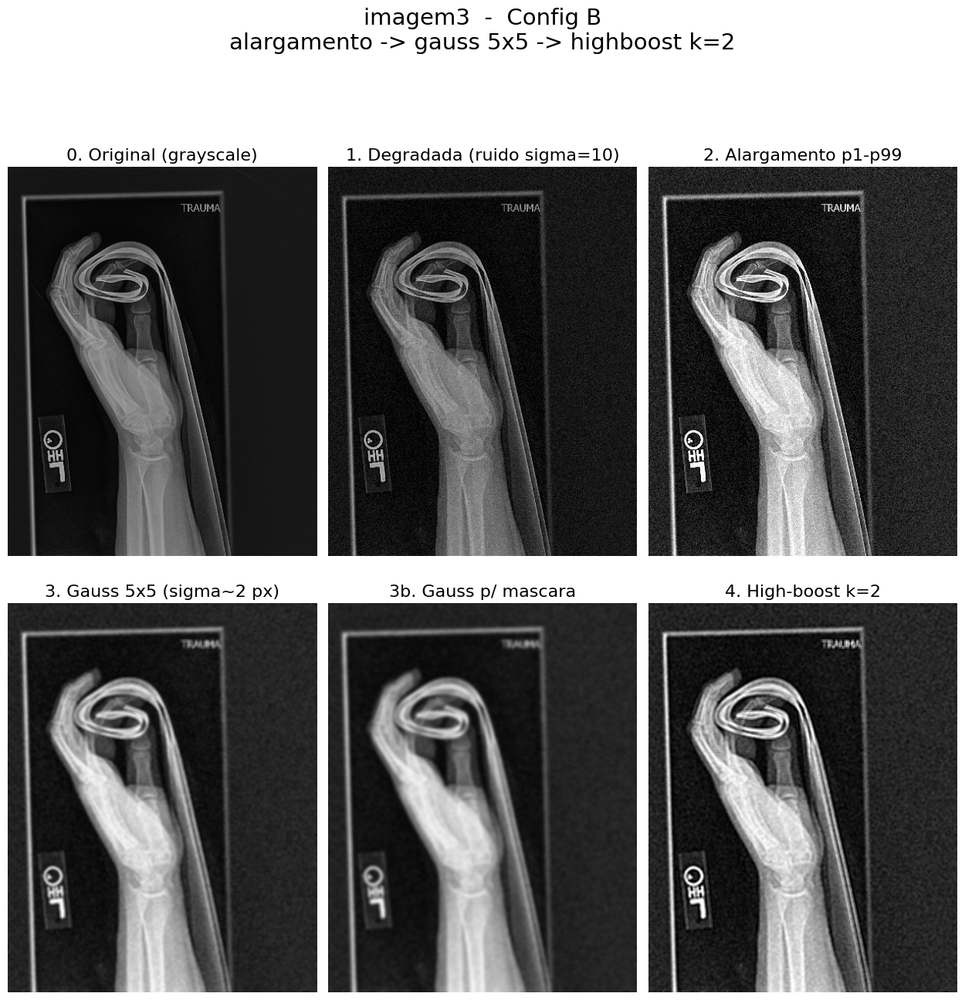

In [48]:
rodar("B", 3)

Configuracao C: alargamento -> gauss 3x3 -> laplaciano c=1

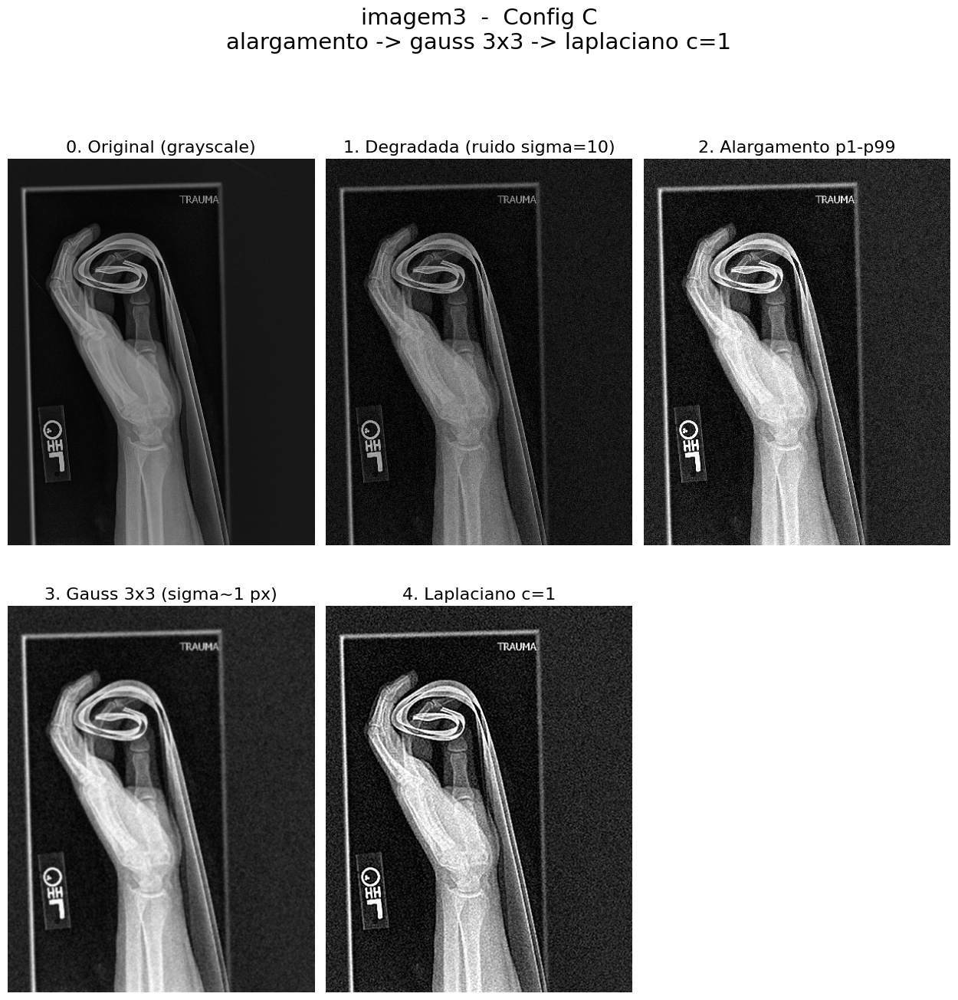

In [49]:
rodar("C", 3)

Configuracao D: gauss 3x3 -> alargamento -> highboost k=1


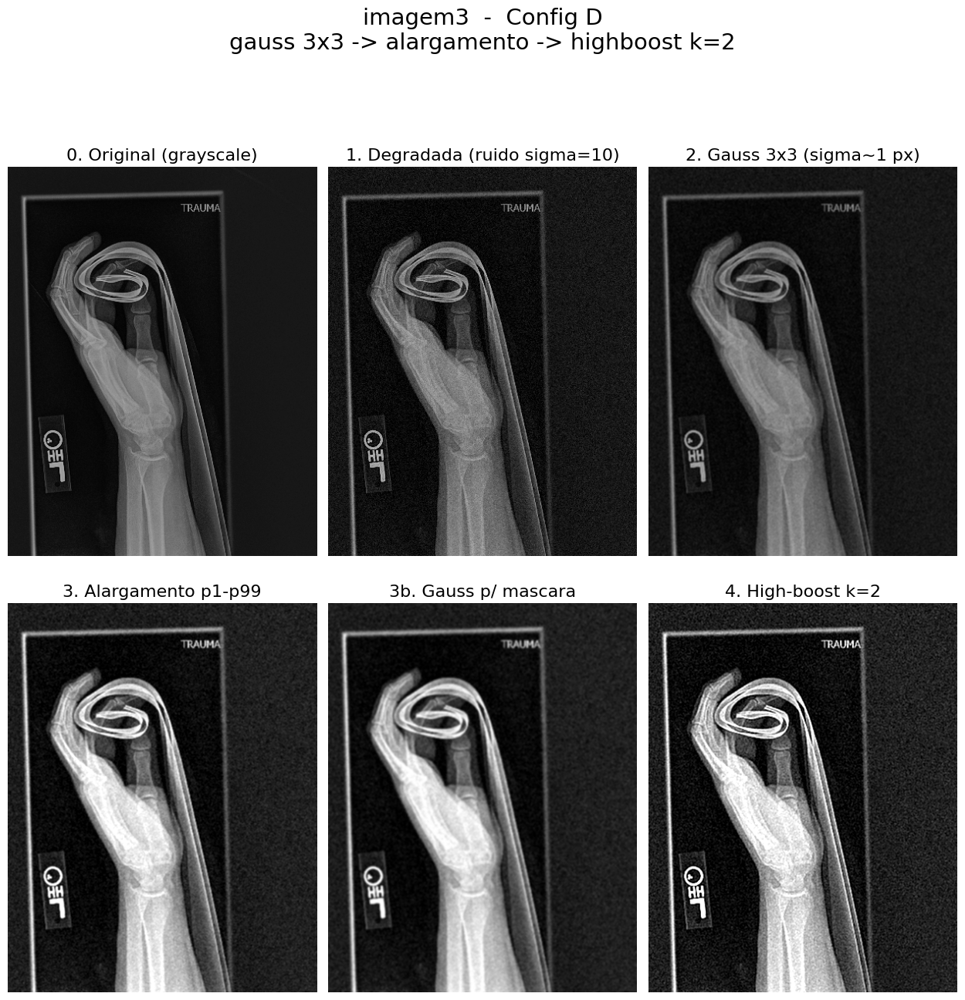

In [50]:
rodar("D", 3)

Comparacao das quatro configuracoes na imagem 3






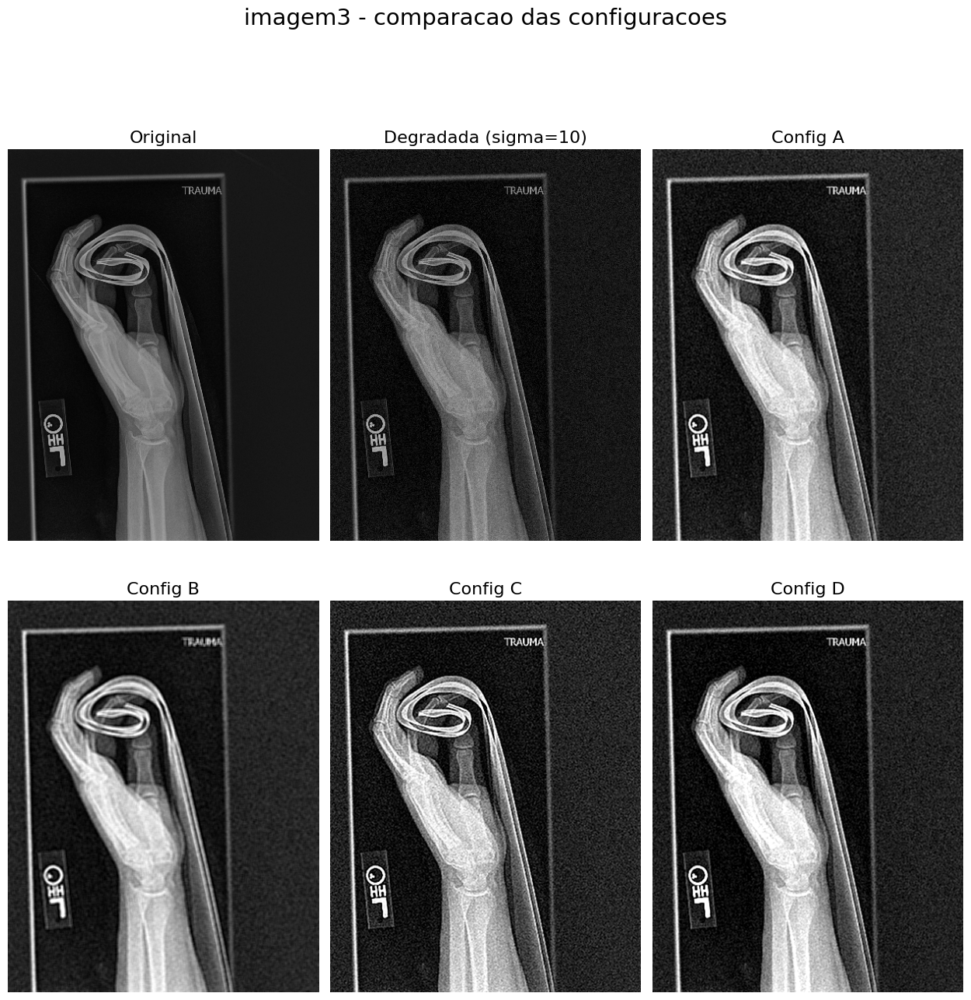


Referencia: ideal
Config         PSNR(dB)       SSIM
sem filtro        23.33     0.9679
A                 24.86     0.9768
B                 23.67     0.9694
C                 23.51     0.9694
D                 25.30     0.9810

Referencia: original
Config         PSNR(dB)       SSIM
degradada         28.47     0.9727
A                 16.63     0.7800
B                 16.64     0.7783
C                 16.30     0.7668
D                 15.73     0.7517

Referencia: degradada
Config         PSNR(dB)       SSIM
A                 16.61     0.7801
B                 16.39     0.7671
C                 16.41     0.7733
D                 15.73     0.7528


In [51]:
comparar(3)